# ¿Chollo o timo? Detector de pisos mal tasados en Valencia · 01. Exploración y limpieza

**Objetivo:** estimar el precio justo de cada vivienda en venta y señalar los anuncios cuyo precio se aleja mucho de esa estimación.

**Datos:** paquete público idealista18, con anuncios reales de idealista en Valencia durante 2018, enriquecidos con datos del Catastro.

# **PREPARACIÓN**

In [ ]:
!pip install -q rdata
!git clone -q --depth 1 https://github.com/paezha/idealista18.git

In [ ]:
import warnings
import pandas as pd
import rdata
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path

 **Carga de datos:**

Los datos vienen en formato de R (.rda). Los leemos con la librería rdata y quitamos la columna de geometría, porque ya tenemos latitud y longitud.

In [ ]:
warnings.filterwarnings("ignore")

datos = rdata.read_rda("idealista18/data/Valencia_Sale.rda")
df = datos["Valencia_Sale"].drop(columns=["geometry"])

print(df.shape)
df.head()

(33622, 41)


,ASSETID,PERIOD,PRICE,UNITPRICE,CONSTRUCTEDAREA,ROOMNUMBER,BATHNUMBER,HASTERRACE,HASLIFT,HASAIRCONDITIONING,...,CADDWELLINGCOUNT,CADASTRALQUALITYID,BUILTTYPEID_1,BUILTTYPEID_2,BUILTTYPEID_3,DISTANCE_TO_CITY_CENTER,DISTANCE_TO_METRO,DISTANCE_TO_BLASCO,LONGITUDE,LATITUDE
1,A9651535568269959084,201812,111000.0,1480.000000,75,2,1,1,1,1,...,35,6,0,0,1,3.759093,0.756517,3.373132,-0.393538,39.500908
2,A13801394133398327300,201812,169000.0,1320.312500,128,4,2,0,1,1,...,56,5,0,0,1,2.073773,0.370680,0.540594,-0.359125,39.482599
3,A8013965313053471366,201812,162000.0,1883.720930,86,2,1,0,1,1,...,20,4,0,0,1,2.099641,0.038560,0.719203,-0.362470,39.485144
4,A15308599866706500727,201812,199000.0,1792.792793,111,4,2,0,1,0,...,25,5,0,0,1,2.120917,0.524827,0.915379,-0.367417,39.487445
5,A7882254711596398998,201812,73000.0,1303.571429,56,3,1,1,1,0,...,20,8,0,0,1,3.087950,1.129985,2.009535,-0.370182,39.497057


# **LIMPIEZA**

**Primer vistazo:**

Revisamos precio, precio por m², superficie, habitaciones y baños. Aparecen valores imposibles, como un piso con 81 habitaciones: hay errores de carga.

In [ ]:
df[["PRICE", "UNITPRICE", "CONSTRUCTEDAREA", "ROOMNUMBER", "BATHNUMBER"]].describe().round(0)

,PRICE,UNITPRICE,CONSTRUCTEDAREA,ROOMNUMBER,BATHNUMBER
count,33622.0,33622.0,33622.0,33622.0,33622.0
mean,199678.0,1715.0,109.0,3.0,2.0
std,177156.0,851.0,47.0,1.0,1.0
min,20000.0,481.0,24.0,0.0,0.0
25%,99000.0,1112.0,80.0,3.0,1.0
50%,151000.0,1531.0,100.0,3.0,2.0
75%,234000.0,2114.0,123.0,4.0,2.0
max,2772000.0,9422.0,912.0,81.0,12.0


**Duplicados:**

Hay unos 33.600 anuncios pero solo unos 27.400 pisos distintos: el mismo piso aparece en varios trimestres.

In [ ]:
print("Anuncios:", len(df))
print("Pisos distintos:", df["ASSETID"].nunique())

Anuncios: 33622
Pisos distintos: 27391


In [ ]:
df = df.sort_values("PERIOD").drop_duplicates("ASSETID", keep="last")
print("Pisos únicos:", len(df))

Pisos únicos: 27391


Nos quedamos con la última versión de cada piso. Si dejáramos los repetidos, el modelo podría ver el mismo piso en entrenamiento y en validación, y su precisión parecería mejor de lo que es (fuga de datos).

# **LIMPIEZA**

Solo eliminamos datos físicamente imposibles (superficie, habitaciones o baños fuera de rango). No eliminamos precios extremos, porque son justo los anuncios que queremos detectar.

In [ ]:
antes = len(df)

df = df[
    (df["CONSTRUCTEDAREA"].between(20, 600)) &
    (df["ROOMNUMBER"] <= 10) &
    (df["BATHNUMBER"] <= 6)
]

print("Eliminados:", antes - len(df))
print("Quedan:", len(df))

Eliminados: 26
Quedan: 27365


# **EXPLORACIÓN**

**Barrio de cada piso:**

Los anuncios solo traen coordenadas. Para saber en qué barrio está cada piso, cruzamos su latitud y longitud con los polígonos (los contornos) de los 73 barrios de Valencia: si el punto cae dentro de un polígono, el piso pertenece a
ese barrio.


In [ ]:

barrios = rdata.read_rda("idealista18/data/Valencia_Polygons.rda", default_encoding="utf8")["Valencia_Polygons"]

puntos = df[["LONGITUDE", "LATITUDE"]].to_numpy()
df["BARRIO"] = None

for _, barrio in barrios.iterrows():
    for poligono in barrio["geometry"]:
        contorno = Path(np.array(poligono[0]))
        dentro = contorno.contains_points(puntos)
        df.loc[dentro, "BARRIO"] = barrio["LOCATIONNAME"]

print("Pisos con barrio asignado:", df["BARRIO"].notna().sum(), "de", len(df))
print("Barrios distintos:", df["BARRIO"].nunique())

Pisos con barrio asignado: 27332 de 27365
Barrios distintos: 73


**Distribución del precio:**

La mayoría de pisos cuestan entre 100.000 y 250.000 €, pero hay unos pocos muy caros que estiran la distribución hacia la derecha. Si aplicamos el logaritmo, la distribución se vuelve casi simétrica.
Por eso el modelo predecirá log(precio): así los errores son relativos (equivocarse un 10% pesa igual en un piso de 100.000 € que en uno de 1 millón), justo lo que necesitamos para detectar anuncios desviados.

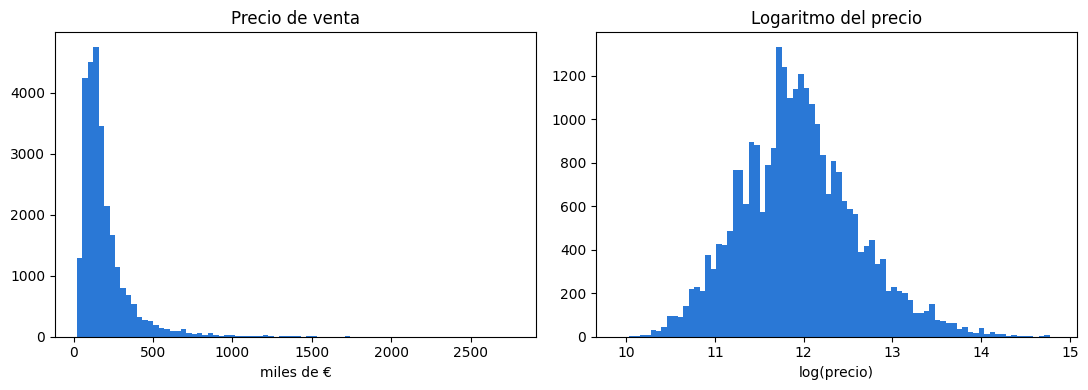

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].hist(df["PRICE"] / 1000, bins=80, color="#2a78d6")
ax[0].set_title("Precio de venta")
ax[0].set_xlabel("miles de €")

ax[1].hist(np.log(df["PRICE"]), bins=80, color="#2a78d6")
ax[1].set_title("Logaritmo del precio")
ax[1].set_xlabel("log(precio)")

plt.tight_layout()
plt.show()

**¿Cuánto vale cada extra?**

Comparamos el precio mediano por m² de los pisos con y sin cada característica.
Ojo: es una comparación descriptiva, no causal. Por ejemplo, los pisos con piscina también suelen ser más nuevos y estar en otras zonas. El modelo separará esos efectos más adelante.

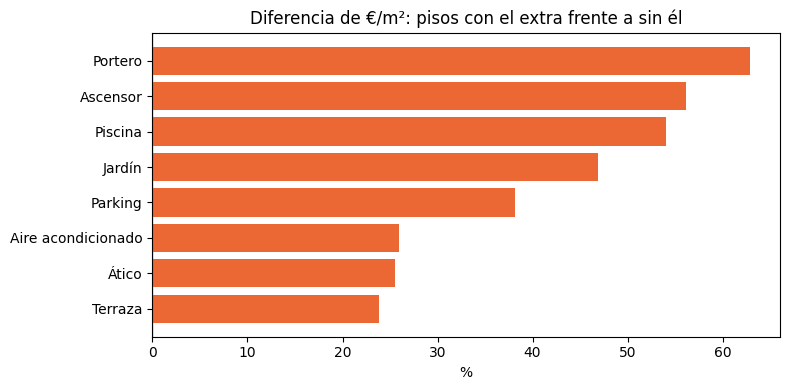

,extra,diferencia_%
1,Terraza,23.8
7,Ático,25.5
2,Aire acondicionado,25.9
3,Parking,38.2
6,Jardín,46.9
4,Piscina,54.0
0,Ascensor,56.2
5,Portero,62.9


In [ ]:
extras = {
    "HASLIFT": "Ascensor",
    "HASTERRACE": "Terraza",
    "HASAIRCONDITIONING": "Aire acondicionado",
    "HASPARKINGSPACE": "Parking",
    "HASSWIMMINGPOOL": "Piscina",
    "HASDOORMAN": "Portero",
    "HASGARDEN": "Jardín",
    "ISINTOPFLOOR": "Ático",
}

resultados = []
for columna, nombre in extras.items():
    con = df.loc[df[columna] == 1, "UNITPRICE"].median()
    sin = df.loc[df[columna] == 0, "UNITPRICE"].median()
    resultados.append({"extra": nombre, "diferencia_%": round((con / sin - 1) * 100, 1)})

efecto = pd.DataFrame(resultados).sort_values("diferencia_%")

plt.figure(figsize=(8, 4))
plt.barh(efecto["extra"], efecto["diferencia_%"], color="#eb6834")
plt.axvline(0, color="grey", linewidth=1)
plt.title("Diferencia de €/m²: pisos con el extra frente a sin él")
plt.xlabel("%")
plt.tight_layout()
plt.show()

efecto

Los extras que más se asocian a un precio por m² alto son portero, ascensor y piscina.

**Un primer detector ingenuo:**

Antes de entrenar un modelo, probamos lo más sencillo: comparar el €/m² de cada piso con la mediana de su barrio. Si un piso cuesta más del doble que la mediana de su barrio, lo marcamos como “caro”; si cuesta menos de la mitad, como “barato”.

In [ ]:
mediana_barrio = df.groupby("BARRIO")["UNITPRICE"].transform("median")
df["RATIO_BARRIO"] = df["UNITPRICE"] / mediana_barrio

df["ALERTA"] = "normal"
df.loc[df["RATIO_BARRIO"] > 2, "ALERTA"] = "caro"
df.loc[df["RATIO_BARRIO"] < 0.5, "ALERTA"] = "barato"

df["ALERTA"].value_counts()

,count
ALERTA,
normal,26415
caro,524
barato,426


**¿Funciona?**

Miramos el estado de los pisos marcados. Si entre los “baratos” hay muchos pisos a reformar, el detector no está encontrando pisos mal tasados, sino simplemente pisos en peor estado.

In [ ]:
df["ESTADO"] = "desconocido"
df.loc[df["BUILTTYPEID_1"] == 1, "ESTADO"] = "obra nueva"
df.loc[df["BUILTTYPEID_2"] == 1, "ESTADO"] = "a reformar"
df.loc[df["BUILTTYPEID_3"] == 1, "ESTADO"] = "buen estado"

pd.crosstab(df["ALERTA"], df["ESTADO"], normalize="index").mul(100).round(1)

ESTADO,a reformar,buen estado,obra nueva
ALERTA,,,
barato,30.0,69.7,0.2
caro,1.9,86.1,12.0
normal,12.8,84.0,3.1


**Conclusión:** el detector ingenuo confunde “distinto del barrio” con “mal tasado”. Entre los pisos marcados como baratos, el 30% están a reformar (frente al 12,8% del resto), y entre los caros, el 12% son obra nueva (frente al 3,1%).
Necesitamos comparar cada piso con lo que debería costar teniendo en cuenta todas sus características, no solo el barrio. Eso es lo que hará el modelo de precio justo.

**Guardar los datos limpios:**

Antes de guardar, quitamos las columnas del detector ingenuo (RATIO_BARRIO y ALERTA), porque se calcularon a partir del precio. Si el modelo las viera, estaría usando el precio para predecir el precio: un caso de fuga de datos.

In [ ]:
df_limpio = df.drop(columns=["RATIO_BARRIO", "ALERTA"])

df_limpio.to_csv("valencia_limpio.csv", index=False)
print("Guardado:", df_limpio.shape)

Guardado: (27365, 43)


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
carpeta = "/content/drive/MyDrive/detector-pisos"
os.makedirs(carpeta, exist_ok=True)

df_limpio.to_csv(f"{carpeta}/valencia_limpio.csv", index=False)
print("Guardado en Drive:", carpeta)

Mounted at /content/drive
Guardado en Drive: /content/drive/MyDrive/detector-pisos
